In [70]:
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt 
import sklearn
import seaborn as sns

In [71]:
df = pd.read_csv("rendimiento_estudiantes.csv", sep=";")

In [72]:
df.head(20)

,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado
5,casado/a,mayor_de_23_anos,1,gestion_nocturno,vespertina,educacion_basica_3er_ciclo_o_equivalente,133.1,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,5,17,5,11.500000,5,16.2,0.3,-0.92,graduado
6,soltero/a,1a_fase_contingente_general,1,enfermeria,diurna,educacion_secundaria,142.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,8,8,8,14.345000,0,15.5,2.8,-4.06,graduado
7,soltero/a,3a_fase_contingente_general,4,turismo,diurna,educacion_secundaria,119.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,5,5,0,0.000000,0,15.5,2.8,-4.06,abandono
8,soltero/a,1a_fase_contingente_general,3,servicio_social,diurna,educacion_secundaria,137.0,rumana,educacion_secundaria_12o_ano_o_equivalente,educacion_secundaria_12o_ano_o_equivalente,...,0,6,7,6,14.142857,0,16.2,0.3,-0.92,graduado
9,soltero/a,1a_fase_contingente_general,1,servicio_social,diurna,educacion_secundaria,138.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_basica_3er_ciclo_o_equivalente,...,0,6,14,2,13.500000,0,8.9,1.4,3.51,abandono


Voy a realizar un Análisis exploratorio de los datos que va a consistir en lo siguiente: 

1. Inspeccion inicial y estructura 
- Carga y dimensiones: Importar el CSV y verificar cuántas filas y columnas tienes.


- Tipos de variables: Identificar cuáles son numéricas (ej. nota_media_1sem, edad_al_matricularse) y cuáles son categóricas (ej. estado_civil, curso, objetivo).

- Resumen estadístico: Usar medidas como la media, mediana y desviación estándar para variables numéricas, y frecuencias para las categóricas.

In [73]:
# Identificar variables numéricas (X) y categóricas (Y)
num_vars = df.select_dtypes(include=['number'])
cat_vars = df.select_dtypes(exclude=['number'])

print(f"El dataset tiene {df.shape[0]} observaciones y {df.shape[1]} variables")
print(f"De estas variables, {num_vars.shape[1]} son variables numéricas y {cat_vars.shape[1]} son variables categóricas")
print(f"\nLas variables numéricas incluyen: {num_vars.columns}")
print(f"\nLas variables categóricas incluyen: {cat_vars.columns}")

El dataset tiene 4424 observaciones y 37 variables
De estas variables, 19 son variables numéricas y 18 son variables categóricas

Las variables numéricas incluyen: Index(['orden_solicitud', 'nota_cualificacion_previa', 'nota_admision',
       'edad_al_matricularse', 'asignaturas_1sem_convalidadas',
       'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas',
       'asignaturas_1sem_aprobadas', 'nota_media_1sem',
       'asignaturas_1sem_sin_evaluacion', 'asignaturas_2sem_convalidadas',
       'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas',
       'asignaturas_2sem_aprobadas', 'nota_media_2sem',
       'asignaturas_2sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion',
       'pib'],
      dtype='object')

Las variables categóricas incluyen: Index(['estado_civil', 'modo_solicitud', 'curso',
       'asistencia_diurna_vespertina', 'cualificacion_previa', 'nacionalidad',
       'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre',
       'ocupacion_pa

In [74]:
#Resumen variables numéricas 
df.describe()

,orden_solicitud,nota_cualificacion_previa,nota_admision,edad_al_matricularse,asignaturas_1sem_convalidadas,asignaturas_1sem_matriculadas,asignaturas_1sem_evaluadas,asignaturas_1sem_aprobadas,nota_media_1sem,asignaturas_1sem_sin_evaluacion,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.727848,132.613314,126.978119,23.265145,0.709991,6.270570,8.299051,4.706600,10.640822,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,1.313793,13.188332,14.482001,7.587816,2.360507,2.480178,4.179106,3.094238,4.843663,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,0.000000,95.000000,95.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,125.000000,117.900000,19.000000,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,133.100000,126.100000,20.000000,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,2.000000,140.000000,134.800000,25.000000,0.000000,7.000000,10.000000,6.000000,13.400000,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,9.000000,190.000000,190.000000,70.000000,20.000000,26.000000,45.000000,26.000000,18.875000,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


Como podemos observar, en muchos casos el numero de asignaturas_evaluadas es mayor al número de asignaturas_matriculadas. 
**MOTIVO??**
ratio_evaluacion = asignaturas_evaluadas / asignaturas_matriculadas. Verás que este ratio se comporta de forma muy distinta entre los que se gradúan y los que abandonan.

In [75]:
#Resumen variables categóricas
df.describe(include=['object'])

,estado_civil,modo_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,ocupacion_madre,ocupacion_padre,desplazado,necesidades_educativas_especiales,deudor,matricula_al_dia,genero,becado,internacional,objetivo
count,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424
unique,6,18,17,2,17,21,29,34,32,46,2,2,2,2,2,2,2,3
top,soltero/a,1a_fase_contingente_general,enfermeria,diurna,educacion_secundaria,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,trabajadoras_no_cualificadas,trabajadores_no_cualificados,si,no,no,si,mujer,no,no,graduado
freq,3919,1708,766,3941,3717,4314,1069,1209,1577,1010,2426,4373,3921,3896,2868,3325,4314,2209


2. ANÁLSIS DE LA VARIABLE OBJETIVO y DE VARIABLES INDIVIDUALES
- desbalanceo de clases 
- distribuciones de las edades, las notas 
- deteccion de outliers

In [76]:
df['objetivo'].value_counts(normalize=True)*100

objetivo
graduado       49.932188
abandono       32.120253
matriculado    17.947559
Name: proportion, dtype: float64

Como podemos observar, la clase "Matriculado" es la más desbalanceada. Esto es lógico, pues se trata de una variables de transicion ya que en algun momento, todos aquellos estudiantes en el marco de 'matriculado', pasarán a ser graduados o abandonos. 
- No podemos confiar solo en el Accuracy, tenemos que utilizar otras métricas como F1-Score, Precision, recall o la matriz de confusion.
- Vamos a querer penalizar más los errores en la clase minoritaria.

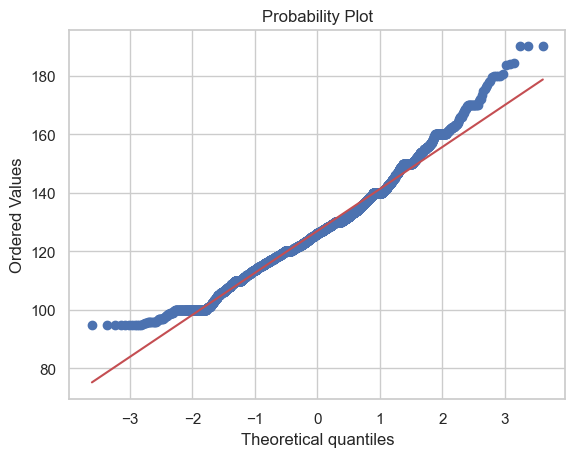

In [77]:
stats.probplot(df['nota_admision'], dist="norm", plot=plt)
plt.show()

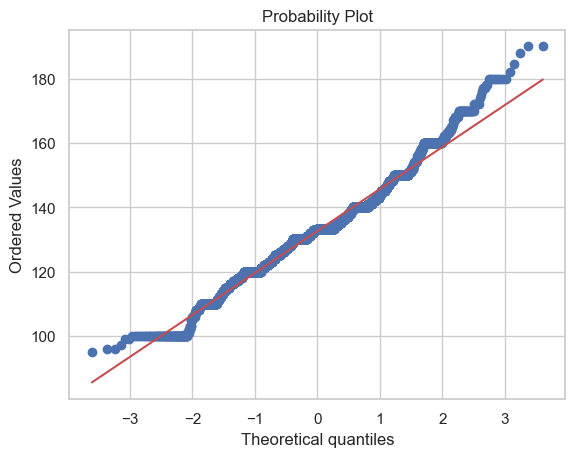

In [78]:
stats.probplot(df['nota_cualificacion_previa'], dist="norm", plot=plt)
plt.show()

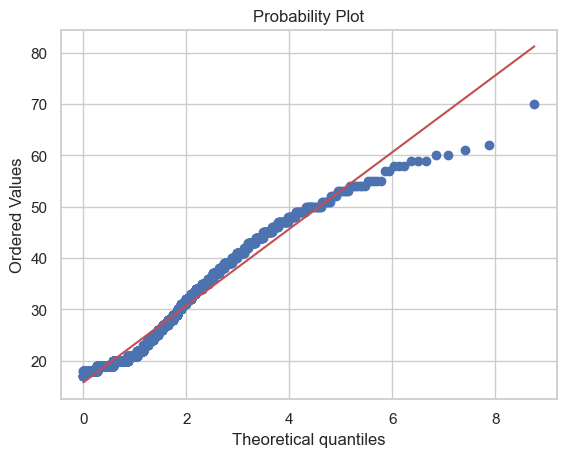

In [79]:
stats.probplot(df['edad_al_matricularse'], dist="expon", plot=plt)
plt.show()

# LIMPIEZA DE VALORES FALTANTES 

## 1. Variables Numéricas 

In [80]:
num_vars.columns

Index(['orden_solicitud', 'nota_cualificacion_previa', 'nota_admision',
       'edad_al_matricularse', 'asignaturas_1sem_convalidadas',
       'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas',
       'asignaturas_1sem_aprobadas', 'nota_media_1sem',
       'asignaturas_1sem_sin_evaluacion', 'asignaturas_2sem_convalidadas',
       'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas',
       'asignaturas_2sem_aprobadas', 'nota_media_2sem',
       'asignaturas_2sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion',
       'pib'],
      dtype='object')

In [81]:
# Variable a tratar
col = 'asignaturas_1sem_evaluadas'

# 1. Cálculo de Cuartiles y Límites
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# 2. Identificar las observaciones exactas (Outliers)
outliers_totales = df[(df[col] < limite_inferior) | (df[col] > limite_superior)]

print(f"--- Análisis de Outliers para: {col} ---")
print(f"Límites: [{limite_inferior}, {limite_superior}]")
print(f"Número de outliers detectados: {len(outliers_totales)}")

# Mostrar las primeras filas detectadas como outliers
print("\n--- Observaciones identificadas como Outliers ---")
print(outliers_totales[[col, 'objetivo']].head(10))

# 3. Aplicar Capping (Limitar los valores a los bordes estadísticos)
# Usamos el método .clip() de pandas que es el más eficiente para esto
df[col] = df[col].clip(lower=limite_inferior, upper=limite_superior)

print(f"\n--- Verificación tras el Capping ---")
print(f"Nuevo valor máximo: {df[col].max()}")
print(f"Nuevo valor mínimo: {df[col].min()}")

--- Análisis de Outliers para: asignaturas_1sem_evaluadas ---
Límites: [0.0, 16.0]
Número de outliers detectados: 158

--- Observaciones identificadas como Outliers ---
     asignaturas_1sem_evaluadas     objetivo
82                           17     abandono
90                           18     abandono
103                          19     graduado
180                          21     graduado
186                          18  matriculado
241                          19  matriculado
262                          17     abandono
346                          24  matriculado
363                          18     graduado
384                          19     graduado

--- Verificación tras el Capping ---
Nuevo valor máximo: 16
Nuevo valor mínimo: 0


## 2. Variables categóricas

In [82]:
cat_cols = df.select_dtypes(include=['object']).columns

print("--- REVISIÓN DE CATEGORÍAS POR VARIABLE ---")
for col in cat_cols:
    # Obtenemos los valores únicos
    valores = df[col].unique()
    print(f"\nVariable: {col}")
    print(f"Valores encontrados: {valores}")

--- REVISIÓN DE CATEGORÍAS POR VARIABLE ---

Variable: estado_civil
Valores encontrados: ['soltero/a' 'casado/a' 'divorciado/a' 'viudo/a' 'union_de_hecho'
 'separado/a_legalmente']

Variable: modo_solicitud
Valores encontrados: ['2a_fase_contingente_general' 'estudiante_internacional_licenciatura'
 '1a_fase_contingente_general' 'mayor_de_23_anos'
 '3a_fase_contingente_general' 'titular_de_diploma_de_ciclo_corto'
 'titular_de_diploma_de_especializacion_tecnologica'
 'cambio_de_institucion_curso' 'cambio_de_curso'
 'titular_de_otro_curso_superior' 'traslado'
 '1a_fase_contingente_especial_madeira'
 '1a_fase_contingente_especial_azores' 'ordenanza_612_93'
 'ordenanza_854_b_99' 'cambio_de_institucion_curso_internacional'
 'ordenanza_533_a_99_apartado_b2_plan_diferente'
 'ordenanza_533_a_99_apartado_b3_otra_institucion']

Variable: curso
Valores encontrados: ['animacion_y_diseno_multimedia' 'turismo' 'diseno_de_comunicacion'
 'periodismo_y_comunicacion' 'servicio_social_nocturno' 'gestion_n

In [83]:
# vamos a agrupar todos los datos faltantes en una unica etiqueta

# Lista de términos que representan falta de información en tu dataset
nulos_texto = ['desconocido', 'en_blanco', 'otra_situacion']

# Opción A: Convertirlos a una categoría única "sin_info"
df = df.replace(nulos_texto, 'informacion_no_disponible')

# Opción B: Si prefieres que Python los reconozca como nulos reales (NaN)
# import numpy as np
# df = df.replace(nulos_texto, np.nan)

# Comprobación rápida para tu memoria
print("Nuevos conteos de información no disponible:")
print(df['ocupacion_madre'].value_counts().get('informacion_no_disponible', 0))

Nuevos conteos de información no disponible:
87


# Train-Test Split 

In [ ]:
from sklearn.model_selection import train_test_split

# Definir características (X) y objetivo (y)
X_clas = df.drop(columns=['objetivo'])
y_clas = df['objetivo']

# Realizar el split 80/20 con estratificación
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clas, y_clas, 
    test_size=0.20, 
    random_state=42, 
    stratify=y_clas  # Crucial por el desbalanceo
)

print(f"Entrenamiento: {X_train_c.shape[0]} muestras")
print(f"Prueba: {X_test_c.shape[0]} muestras")

X_train_c.to_csv()

Entrenamiento: 3539 muestras
Prueba: 885 muestras


## Código unificando todo



In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Carga del dataset original
df = pd.read_csv('rendimiento_estudiantes.csv', sep=';')

# --- LIMPIEZA GLOBAL ---

# A. Unificación de valores faltantes en variables categóricas
# Justificación: Reducir cardinalidad y estabilizar el peso estadístico.
terminos_nulos = ['desconocido', 'en_blanco', 'otra_situacion']
df = df.replace(terminos_nulos, 'informacion_no_disponible')

# B. Tratamiento de Outliers (Capping) para variables numéricas clave
# Ejemplo aplicado a 'asignaturas_1sem_evaluadas' como discutimos.
def aplicar_capping(data, columna):
    Q1 = data[columna].quantile(0.25)
    Q3 = data[columna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR
    return data[columna].clip(lower=limite_inf, upper=limite_sup)

# Aplicamos el capping a las variables de desempeño que detectamos con outliers
cols_desempeno = ['asignaturas_1sem_evaluadas', 'asignaturas_2sem_evaluadas']
for col in cols_desempeno:
    df[col] = aplicar_capping(df, col)


# --- PREPARACIÓN PARA TAREA 1: CLASIFICACIÓN ---

# Objetivo: Predecir 'objetivo' (Abandono, Matriculado, Graduado).
# Mantenemos todas las variables (incluyendo notas 0.0) por su valor predictivo.
df_clas_train, df_clas_test = train_test_split(
    df, 
    test_size=0.20, 
    random_state=42, 
    stratify=df['objetivo'] # Preservar el desbalanceo de clases
)

# --- PREPARACIÓN PARA TAREA 2: REGRESIÓN ---

# Objetivo: Predecir 'nota_media_2sem'.
# 1. Eliminamos alumnos con nota 0.0 para evitar sesgos de "no presentados".
df_reg = df[df['nota_media_2sem'] > 0].copy()

# 2. Eliminamos variables de Data Leakage (2do semestre) según el PDF.
vars_leakage = [
    'asignaturas_2sem_aprobadas', 'asignaturas_2sem_evaluadas', 
    'asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas',
    'asignaturas_2sem_sin_evaluacion'
]
df_reg = df_reg.drop(columns=vars_leakage)

# 3. Split 80/20 para regresión
df_reg_train, df_reg_test = train_test_split(
    df_reg, 
    test_size=0.20, 
    random_state=42
)


# --- GENERACIÓN DE FICHEROS ---

# Guardamos en CSV (puedes cambiar la extensión a .dat si lo prefieres)
df_clas_train.to_csv('datos_limpios_clasificacion_train.csv', index=False, sep=';')
df_clas_test.to_csv('datos_limpios_clasificacion_test.csv', index=False, sep=';')

df_reg_train.to_csv('datos_limpios_regresion_train.csv', index=False, sep=';')
df_reg_test.to_csv('datos_limpios_regresion_test.csv', index=False, sep=';')

print("Ficheros generados con éxito:")
print("- Clasificación (Train/Test): 80/20 estratificado.")
print("- Regresión (Train/Test): 80/20 filtrado (sin ceros ni leakage).")

Ficheros generados con éxito:
- Clasificación (Train/Test): 80/20 estratificado.
- Regresión (Train/Test): 80/20 filtrado (sin ceros ni leakage).


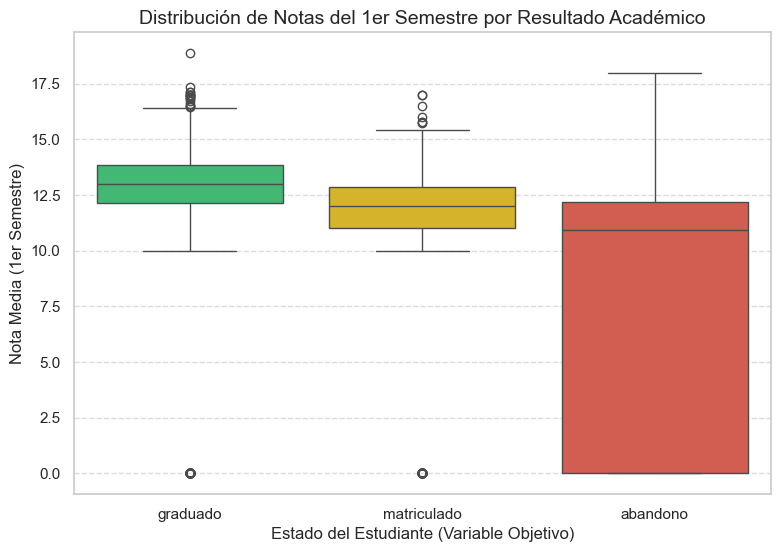

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Asegúrate de que los nombres coinciden con tu CSV y tu informe [cite: 7, 9]
# Usamos hue='objetivo' para evitar el error interno de boxprops
plt.figure(figsize=(9, 6))

colores = {"graduado": "#2ecc71", "matriculado": "#f1c40f", "abandono": "#e74c3c"}

# 2. Crear el gráfico con la sintaxis más estable
ax = sns.boxplot(
    data=df,
    x='objetivo', 
    y='nota_media_1sem', 
    hue='objetivo',       # Definir hue explícitamente evita el error
    palette=colores, 
    order=["graduado", "matriculado", "abandono"],
    legend=False          # Quitamos la leyenda porque el eje X ya lo indica
)

# 3. Personalización alineada con tu sección 2.1.2 [cite: 13, 16]
plt.title('Distribución de Notas del 1er Semestre por Resultado Académico', fontsize=14)
plt.xlabel('Estado del Estudiante (Variable Objetivo)', fontsize=12)
plt.ylabel('Nota Media (1er Semestre)', fontsize=12)

# Añadimos una cuadrícula horizontal para ver mejor el "efecto del cero" 
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.savefig('boxplot_notas.png', dpi=300, bbox_inches='tight')
plt.show()

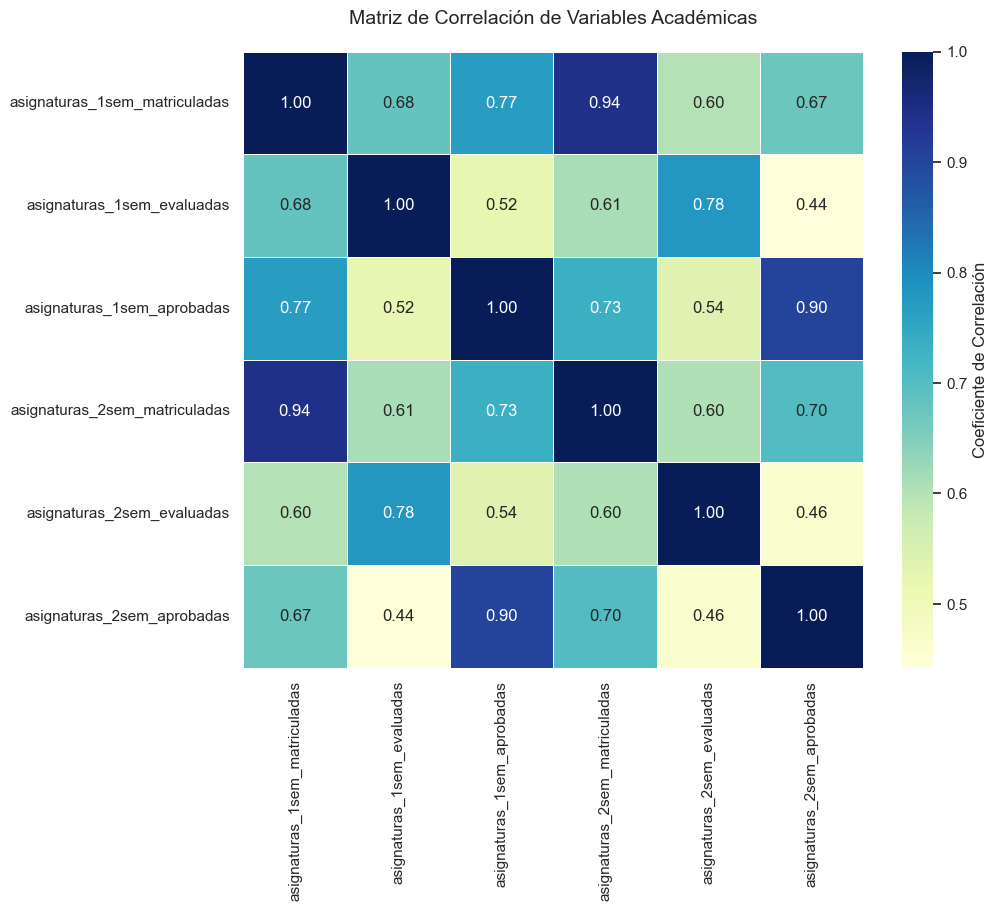

In [23]:
# Seleccionamos las variables del bloque académico 
vars_academicas = [
    'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas',
    'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas'
]

# Calcular la matriz de correlación
corr_matrix = df[vars_academicas].corr()

plt.figure(figsize=(10, 8))

# Cambiamos cmap a 'YlGnBu'. Eliminamos 'center=0' para que la escala sea 
# puramente secuencial y resalte la intensidad de la correlación positiva.
sns.heatmap(corr_matrix, 
            annot=True, 
            cmap='YlGnBu', 
            fmt=".2f", 
            linewidths=0.5,
            cbar_kws={'label': 'Coeficiente de Correlación'})

plt.title('Matriz de Correlación de Variables Académicas', fontsize=14, pad=20)
plt.savefig('heatmap_correlacion_azul_amarillo.png', dpi=300, bbox_inches='tight')
plt.show()

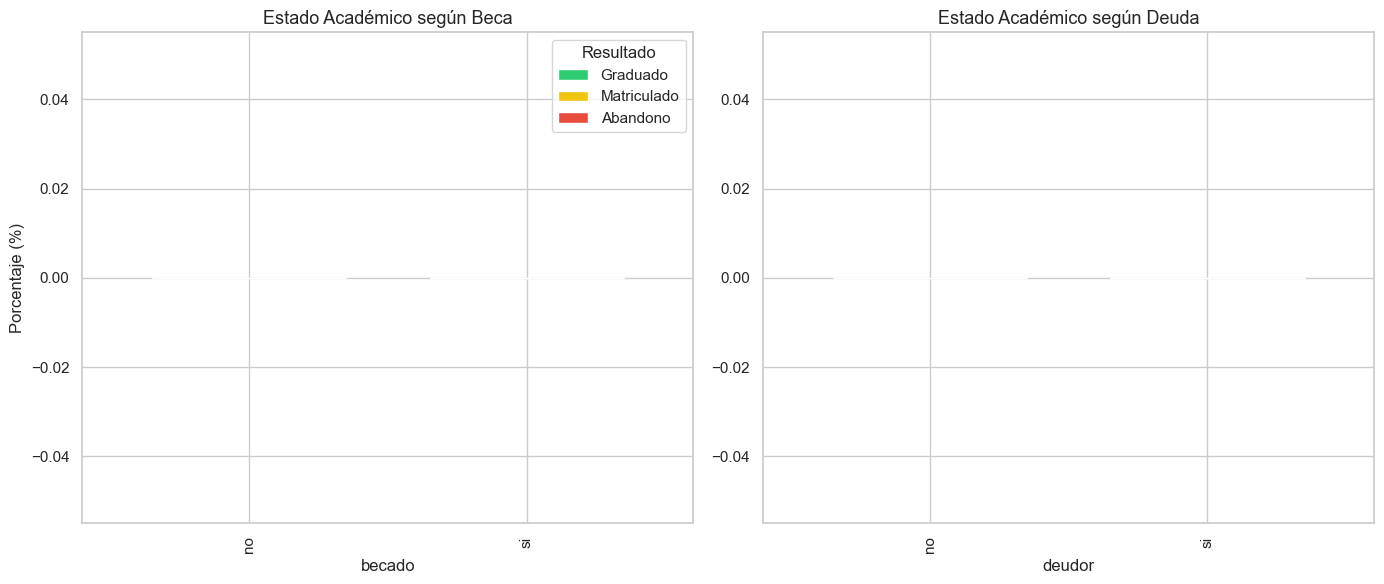

In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Preparar los datos (Proporciones)

df = pd.read_csv('rendimiento_estudiantes.csv', sep=';')

# --- LIMPIEZA GLOBAL ---

# A. Unificación de valores faltantes en variables categóricas
# Justificación: Reducir cardinalidad y estabilizar el peso estadístico.
terminos_nulos = ['desconocido', 'en_blanco', 'otra_situacion']
df = df.replace(terminos_nulos, 'informacion_no_disponible')

def get_pct_df(df, col):
    return (df.groupby(col)['objetivo']
            .value_counts(normalize=True)
            .unstack() * 100).reindex(["Graduado", "Matriculado", "Abandono"], axis=1)

df_beca = get_pct_df(df, 'becado')
df_deuda = get_pct_df(df, 'deudor')

# 2. Configuración estética
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
colores = ["#2ecc71", "#f1c40f", "#e74c3c"] # Verde, Amarillo, Rojo

# Gráfico de Becados
df_beca.plot(kind='bar', stacked=True, color=colores, ax=ax1, width=0.7)
ax1.set_title('Estado Académico según Beca', fontsize=13)
ax1.set_ylabel('Porcentaje (%)')
ax1.legend(title='Resultado', bbox_to_anchor=(1, 1))

# Gráfico de Deudores
df_deuda.plot(kind='bar', stacked=True, color=colores, ax=ax2, width=0.7)
ax2.set_title('Estado Académico según Deuda', fontsize=13)
ax2.set_ylabel('')
ax2.get_legend().remove()

plt.tight_layout()
plt.savefig('proporciones_socioeconomicas.png', dpi=300)
plt.show()